# Intelligent Retail Demand Forecasting and Product Recommendation

**Scenario:** An online retailer wants to (1) predict product demand, (2) find frequently purchased product combinations, and (3) recommend relevant products to customers.

**Pipeline implemented in this notebook**

| Step | What we do |
|---|---|
| 1 | Load public dataset (UCI *Online Retail*) - automatic fallback to a documented synthetic dataset |
| 2 | Data processing: cleaning, missing / inconsistent values, feature engineering |
| 3 | Exploratory analysis and visualisations |
| 4 | **Demand forecasting** (baselines vs Linear Regression, Random Forest, Gradient Boosting) |
| 5 | **Pattern mining** (FP-Growth + association rules) |
| 6 | **Recommender system** (Popularity baseline, Item-CF, User-CF, SVD) |
| 7 | Evaluation, demo and export of results |

**Run:** `Runtime -> Run all`. No setup needed in Google Colab.

## 1. Setup

In [ ]:
import sys, subprocess, importlib, io, zipfile, warnings
for pkg in ["mlxtend", "openpyxl", "requests"]:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from mlxtend.frequent_patterns import fpgrowth, association_rules

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4.5)
SEED = 42
np.random.seed(SEED)

# ---- Configuration ----
DATA_SOURCE = "auto"   # "auto" = try UCI, fall back to synthetic | "uci" | "synthetic"
TOP_N_PRODUCTS = 30    # products used for demand forecasting
TEST_WEEKS = 8         # last N weeks are held out for forecast evaluation
TOP_ITEMS_MINING = 150 # items considered for pattern mining
K = 10                 # recommendation list size for evaluation
print("Setup complete")

Setup complete


## 2. Dataset

**Primary source:** [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail) - ~540k transactions (Dec 2010 - Dec 2011) of a UK-based online gift retailer.
Columns: `InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country`.

**Fallback:** if the download is blocked, a *documented synthetic dataset* with the same schema is generated. It contains product categories, seasonality, customer category preferences, product bundles, and deliberately injected dirty records (missing IDs, duplicates, cancellations, zero prices).

In [ ]:
def load_uci_online_retail():
    urls = [
        "https://archive.ics.uci.edu/static/public/352/online+retail.zip",
        "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx",
    ]
    for u in urls:
        try:
            r = requests.get(u, timeout=90)
            r.raise_for_status()
            if u.endswith(".zip"):
                z = zipfile.ZipFile(io.BytesIO(r.content))
                name = [n for n in z.namelist() if n.lower().endswith(".xlsx")][0]
                return pd.read_excel(z.open(name))
            return pd.read_excel(io.BytesIO(r.content))
        except Exception as e:
            print(f"Download failed for {u}: {type(e).__name__}")
    return None


def make_synthetic_retail(seed=42, n_customers=1500, n_products=120,
                          start="2023-01-01", end="2024-12-31"):
    """Synthetic retail transactions with the UCI Online Retail schema."""
    rng = np.random.default_rng(seed)
    cats = ["Home Decor", "Kitchen", "Stationery", "Toys", "Garden", "Gifts", "Bath"]
    cat_of = rng.integers(0, len(cats), n_products)
    price = np.round(rng.lognormal(1.0, 0.6, n_products) + 0.5, 2)
    codes = [f"P{1000 + i}" for i in range(n_products)]
    names = [f"{cats[c].upper()} ITEM {i + 1}" for i, c in enumerate(cat_of)]
    pop = rng.pareto(1.3, n_products) + 1
    pop = pop / pop.sum()
    bundles = [rng.choice(n_products, 3, replace=False) for _ in range(12)]  # co-purchased sets
    pref = [rng.choice(len(cats), 2, replace=False) for _ in range(n_customers)]
    aff = np.ones((n_customers, n_products))
    for c in range(n_customers):
        aff[c, np.isin(cat_of, pref[c])] = 4.0
    month_mult = np.ones((13, n_products))
    for m in range(1, 13):
        for ci, cn in enumerate(cats):
            f = 1.0
            if cn in ("Toys", "Gifts") and m in (11, 12): f = 2.5
            if cn == "Garden" and m in (4, 5, 6, 7): f = 2.0
            if cn == "Home Decor" and m in (10, 11, 12): f = 1.5
            if cn == "Bath" and m in (1, 2): f = 1.4
            month_mult[m, cat_of == ci] = f

    t0 = pd.Timestamp(start)
    rows, inv_no = [], 500000
    for d in pd.date_range(start, end):
        base = (22 * (1 + 0.5 * (d.month in (11, 12))) * (0.45 if d.weekday() == 5 else 1.0)
                * (1 + 0.0004 * (d - t0).days))
        for _ in range(rng.poisson(base)):
            c = int(rng.integers(n_customers))
            w = pop * aff[c] * month_mult[d.month]
            w = w / w.sum()
            if rng.random() < 0.35:
                items = set(bundles[int(rng.integers(len(bundles)))].tolist())
                items |= set(rng.choice(n_products, int(rng.integers(0, 3)), replace=False, p=w).tolist())
            else:
                items = set(rng.choice(n_products, int(rng.integers(2, 8)), replace=False, p=w).tolist())
            ts = d + pd.Timedelta(hours=int(rng.integers(8, 19)), minutes=int(rng.integers(0, 60)))
            inv_no += 1
            for it in items:
                rows.append((str(inv_no), codes[it], names[it], int(rng.poisson(3)) + 1,
                             ts, float(price[it]), float(c + 10000), "United Kingdom"))

    df = pd.DataFrame(rows, columns=["InvoiceNo", "StockCode", "Description", "Quantity",
                                     "InvoiceDate", "UnitPrice", "CustomerID", "Country"])
    # ---- inject dirty data so the cleaning step is meaningful ----
    n = len(df)
    df.loc[rng.random(n) < 0.04, "CustomerID"] = np.nan                       # missing customers
    df.loc[rng.random(n) < 0.002, "Description"] = np.nan                     # missing descriptions
    df.loc[rng.random(n) < 0.003, "UnitPrice"] = 0.0                          # invalid prices
    mask = rng.random(n) < 0.01                                               # inconsistent text
    df.loc[mask, "Description"] = df.loc[mask, "Description"].str.lower() + " "
    canc = df.sample(frac=0.015, random_state=seed).copy()                    # cancellations
    canc["InvoiceNo"] = "C" + canc["InvoiceNo"]
    canc["Quantity"] = -canc["Quantity"]
    post = df.sample(200, random_state=seed).copy()                           # non-product rows
    post["StockCode"], post["Description"] = "POST", "POSTAGE"
    df = pd.concat([df, df.sample(frac=0.01, random_state=seed), canc, post], ignore_index=True)  # duplicates too
    return df.sample(frac=1, random_state=seed).sort_values("InvoiceDate").reset_index(drop=True)


raw = None
if DATA_SOURCE in ("auto", "uci"):
    raw = load_uci_online_retail()
if raw is None:
    if DATA_SOURCE == "uci":
        raise RuntimeError("Could not download the UCI dataset. Use DATA_SOURCE='auto' or 'synthetic'.")
    print("Using SYNTHETIC dataset (documented in the markdown above).")
    raw = make_synthetic_retail(SEED)
    DATASET_NAME = "Synthetic retail data"
else:
    DATASET_NAME = "UCI Online Retail"
print(f"Dataset: {DATASET_NAME} | shape = {raw.shape}")
raw.head()

Dataset: UCI Online Retail | shape = (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Data processing
Steps: remove duplicates -> drop cancellations -> remove invalid quantity/price -> remove non-product codes -> fix inconsistent descriptions -> handle missing values -> cap outliers -> engineer features.

In [ ]:
print("Missing values BEFORE cleaning:")
print(raw.isna().sum()[lambda s: s > 0].to_string(), "\n")

df = raw.drop_duplicates().copy()
n0 = len(df)
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str).str.strip().str.upper()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df = df[~df["InvoiceNo"].str.startswith("C")]                  # cancellations
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]          # invalid values
df = df[df["StockCode"].str.contains(r"\d")]                   # POST, DOT, M, BANK CHARGES ...
df = df.dropna(subset=["Description"]).copy()                  # no product name -> unusable
df["Description"] = df["Description"].str.strip().str.upper()
# inconsistent descriptions: keep most frequent name per StockCode
name_map = df.groupby("StockCode")["Description"].agg(lambda s: s.mode().iloc[0])
df["Description"] = df["StockCode"].map(name_map)

# CustomerID missing: kept for demand + pattern mining (not customer specific); dropped for recommender
df["CustomerID"] = df["CustomerID"].astype("Int64").astype("string")

# outliers: cap extreme quantities / prices at the 99.9th percentile
q_cap, p_cap = df["Quantity"].quantile(0.999), df["UnitPrice"].quantile(0.999)
df["Quantity"] = df["Quantity"].clip(upper=q_cap)
df["UnitPrice"] = df["UnitPrice"].clip(upper=p_cap)

# feature engineering
df["Revenue"] = df["Quantity"] * df["UnitPrice"]
df["Date"] = df["InvoiceDate"].dt.normalize()
df["Week"] = df["InvoiceDate"].dt.to_period("W").dt.start_time
df["Month"] = df["InvoiceDate"].dt.to_period("M").dt.start_time
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour

print(f"Rows: raw={len(raw):,} -> cleaned={len(df):,}  (removed {len(raw) - len(df):,})")
print(f"Products: {df['StockCode'].nunique():,} | Invoices: {df['InvoiceNo'].nunique():,} | "
      f"Customers: {df['CustomerID'].nunique():,} | Missing CustomerID rows: {df['CustomerID'].isna().sum():,}")
print(f"Period: {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")
df.head()

Missing values BEFORE cleaning:
Description      1454
CustomerID     135080 

Rows: raw=541,909 -> cleaned=522,685  (removed 19,224)
Products: 3,802 | Invoices: 19,776 | Customers: 4,334 | Missing CustomerID rows: 131,402
Period: 2010-12-01 to 2011-12-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Date,Week,Month,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12-01,2010-11-29,2010-12-01,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010-11-29,2010-12-01,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12-01,2010-11-29,2010-12-01,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010-11-29,2010-12-01,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010-11-29,2010-12-01,Wednesday,8


## 4. Exploratory analysis (visualisations 1-4)

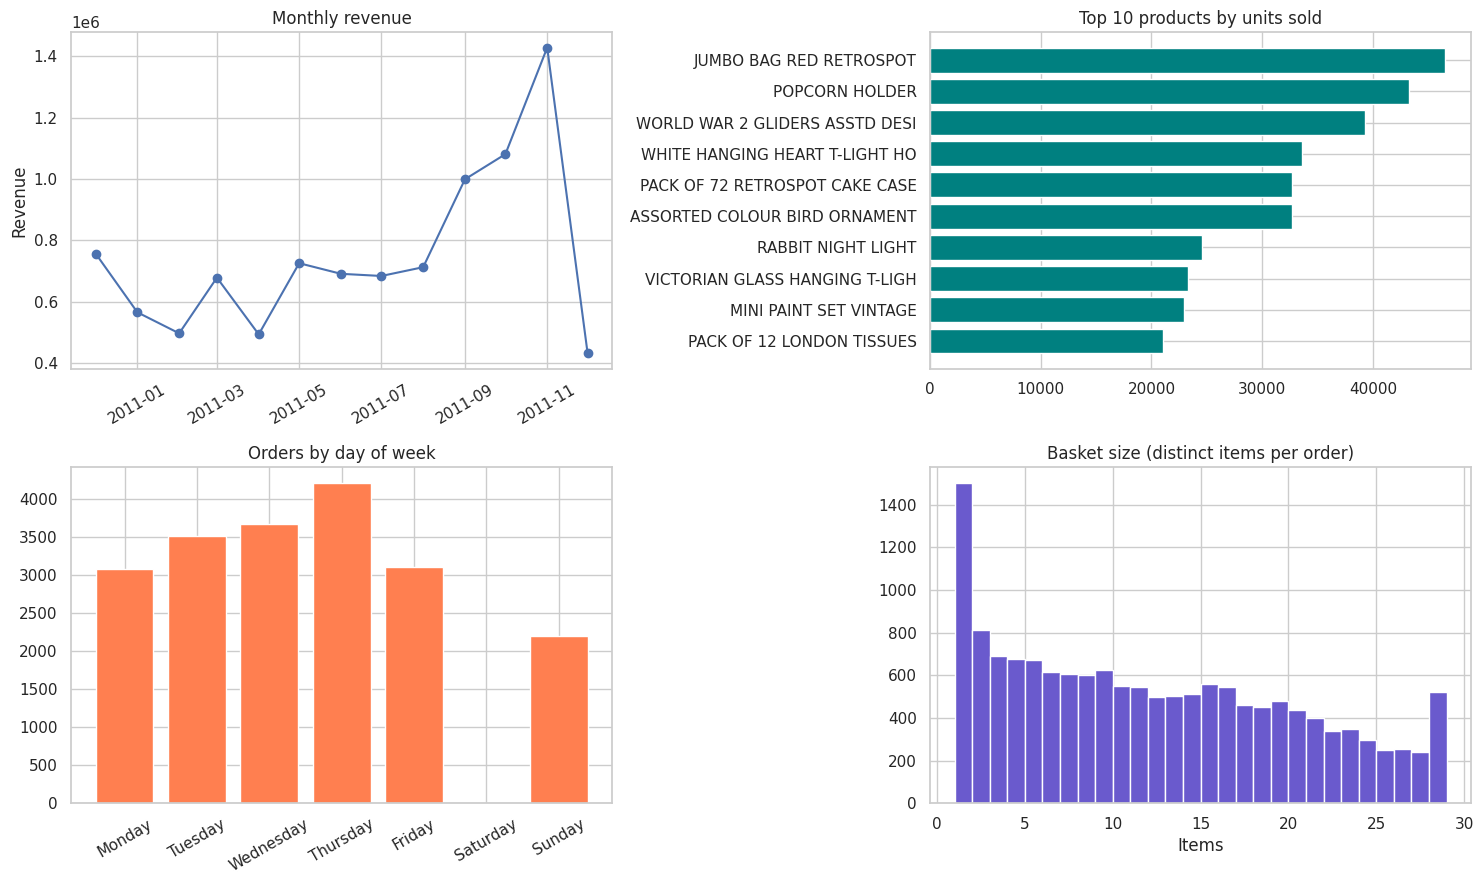

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

monthly = df.groupby("Month")["Revenue"].sum()
axes[0, 0].plot(monthly.index, monthly.values, marker="o")
axes[0, 0].set_title("Monthly revenue"); axes[0, 0].set_ylabel("Revenue"); axes[0, 0].tick_params(axis="x", rotation=30)

top10 = df.groupby("Description")["Quantity"].sum().nlargest(10).sort_values()
axes[0, 1].barh([s[:30] for s in top10.index], top10.values, color="teal")
axes[0, 1].set_title("Top 10 products by units sold")

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = df.groupby("DayOfWeek")["InvoiceNo"].nunique().reindex(order).fillna(0)
axes[1, 0].bar(dow.index, dow.values, color="coral")
axes[1, 0].set_title("Orders by day of week"); axes[1, 0].tick_params(axis="x", rotation=30)

axes[1, 1].hist(df.groupby("InvoiceNo")["StockCode"].nunique(), bins=range(1, 30), color="slateblue")
axes[1, 1].set_title("Basket size (distinct items per order)"); axes[1, 1].set_xlabel("Items")
plt.tight_layout(); plt.show()

## 5. Demand forecasting
**Task:** predict next week's units sold for each of the top-N products.

**Features (no data leakage - only past information):** lag 1-4 weeks, rolling mean/std (4 & 8 weeks), last week's order count, price, price change, week-of-year, month, and a product-level mean demand computed from the training period only.

**Models:** two naive baselines (last week, 4-week moving average) vs Linear Regression, Random Forest and Gradient Boosting. Evaluation uses a **time-based split** (last `TEST_WEEKS` weeks = test set).

In [ ]:
# drop first/last (partial) weeks, keep top-N products
wk = df[(df["Week"] > df["Week"].min()) & (df["Week"] < df["Week"].max())]
top_products = wk.groupby("StockCode")["Quantity"].sum().nlargest(TOP_N_PRODUCTS).index
weekly = (wk[wk["StockCode"].isin(top_products)]
          .groupby(["StockCode", "Week"])
          .agg(Quantity=("Quantity", "sum"), Price=("UnitPrice", "mean"), Orders=("InvoiceNo", "nunique"))
          .reset_index())

last_actual_week = wk["Week"].max()
future_week = last_actual_week + pd.Timedelta(weeks=1)
weeks = pd.date_range(wk["Week"].min(), future_week, freq="7D")
grid = (pd.MultiIndex.from_product([top_products, weeks], names=["StockCode", "Week"])
        .to_frame(index=False).merge(weekly, on=["StockCode", "Week"], how="left"))
is_future = grid["Week"] == future_week
grid.loc[~is_future, ["Quantity", "Orders"]] = grid.loc[~is_future, ["Quantity", "Orders"]].fillna(0)
grid["Price"] = grid.groupby("StockCode")["Price"].transform(lambda s: s.ffill().bfill())  # missing weeks -> last known price

g = grid.groupby("StockCode")
for l in [1, 2, 3, 4]:
    grid[f"lag_{l}"] = g["Quantity"].shift(l)
grid["roll_mean_4"] = g["Quantity"].transform(lambda s: s.shift(1).rolling(4).mean())
grid["roll_std_4"] = g["Quantity"].transform(lambda s: s.shift(1).rolling(4).std())
grid["roll_mean_8"] = g["Quantity"].transform(lambda s: s.shift(1).rolling(8).mean())
grid["orders_lag_1"] = g["Orders"].shift(1)
grid["price_change"] = (grid["Price"] / g["Price"].shift(1) - 1).fillna(0)
grid["week_of_year"] = grid["Week"].dt.isocalendar().week.astype(int)
grid["month"] = grid["Week"].dt.month

BASE_FEATS = ["lag_1", "lag_2", "lag_3", "lag_4", "roll_mean_4", "roll_std_4", "roll_mean_8",
              "orders_lag_1", "Price", "price_change", "week_of_year", "month"]
FEATS = BASE_FEATS + ["prod_mean"]

actual_weeks = sorted(grid.loc[~is_future, "Week"].unique())
cutoff = actual_weeks[-TEST_WEEKS]
model_df = grid[~is_future].dropna(subset=BASE_FEATS).copy()
train = model_df[model_df["Week"] < cutoff].copy()
test = model_df[model_df["Week"] >= cutoff].copy()

prod_mean = train.groupby("StockCode")["Quantity"].mean()          # training-period only (no leakage)
for part in (train, test):
    part["prod_mean"] = part["StockCode"].map(prod_mean)

print(f"Weekly panel: {grid['StockCode'].nunique()} products x {len(actual_weeks)} weeks")
print(f"Train rows: {len(train):,} (up to {cutoff.date()}) | Test rows: {len(test):,} ({TEST_WEEKS} weeks)")
train[["StockCode", "Week", "Quantity"] + FEATS].head()

Weekly panel: 30 products x 52 weeks
Train rows: 1,080 (up to 2011-10-10) | Test rows: 240 (8 weeks)


,StockCode,Week,Quantity,lag_1,lag_2,lag_3,lag_4,roll_mean_4,roll_std_4,roll_mean_8,orders_lag_1,Price,price_change,week_of_year,month,prod_mean
8,85099B,2011-01-31,965.0,502.0,594.0,225.0,1374.0,673.75,492.471573,519.250,26.0,2.465814,-0.042259,5,1,903.527778
9,85099B,2011-02-07,288.0,965.0,502.0,594.0,225.0,571.50,305.636494,533.375,43.0,2.662381,0.079717,6,2,903.527778
10,85099B,2011-02-14,985.0,288.0,965.0,502.0,594.0,587.25,282.582584,516.000,21.0,2.510000,-0.057235,7,2,903.527778
11,85099B,2011-02-21,810.0,985.0,288.0,965.0,502.0,685.00,346.168552,616.625,29.0,2.544000,0.013546,8,2,903.527778
12,85099B,2011-02-28,624.0,810.0,985.0,288.0,965.0,762.00,325.534432,717.875,30.0,2.210667,-0.131027,9,2,903.527778


In [ ]:
def forecast_metrics(y, p):
    p = np.clip(p, 0, None)
    return {"MAE": mean_absolute_error(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "WAPE %": 100 * np.abs(y - p).sum() / np.abs(y).sum(),
            "R2": r2_score(y, p)}

X_tr, y_tr, X_te, y_te = train[FEATS], train["Quantity"], test[FEATS], test["Quantity"]

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                   subsample=0.8, random_state=SEED),
}
preds = {"Baseline: Last week": test["lag_1"].values,
         "Baseline: 4-wk moving avg": test["roll_mean_4"].values}
for name, m in models.items():
    m.fit(X_tr, y_tr)
    preds[name] = m.predict(X_te)

results = pd.DataFrame({n: forecast_metrics(y_te.values, p) for n, p in preds.items()}).T.round(3)
print("Demand forecast performance on the held-out test weeks")
results.sort_values("RMSE")

Demand forecast performance on the held-out test weeks


,MAE,RMSE,WAPE %,R2
Baseline: 4-wk moving avg,263.125,403.667,43.076,0.517
Baseline: Last week,296.417,431.884,48.526,0.447
Gradient Boosting,336.993,465.525,55.169,0.357
Linear Regression,307.548,484.747,50.348,0.303
Random Forest,322.384,496.193,52.777,0.269


### Visualisations 5-8: model comparison, actual vs predicted, feature importance

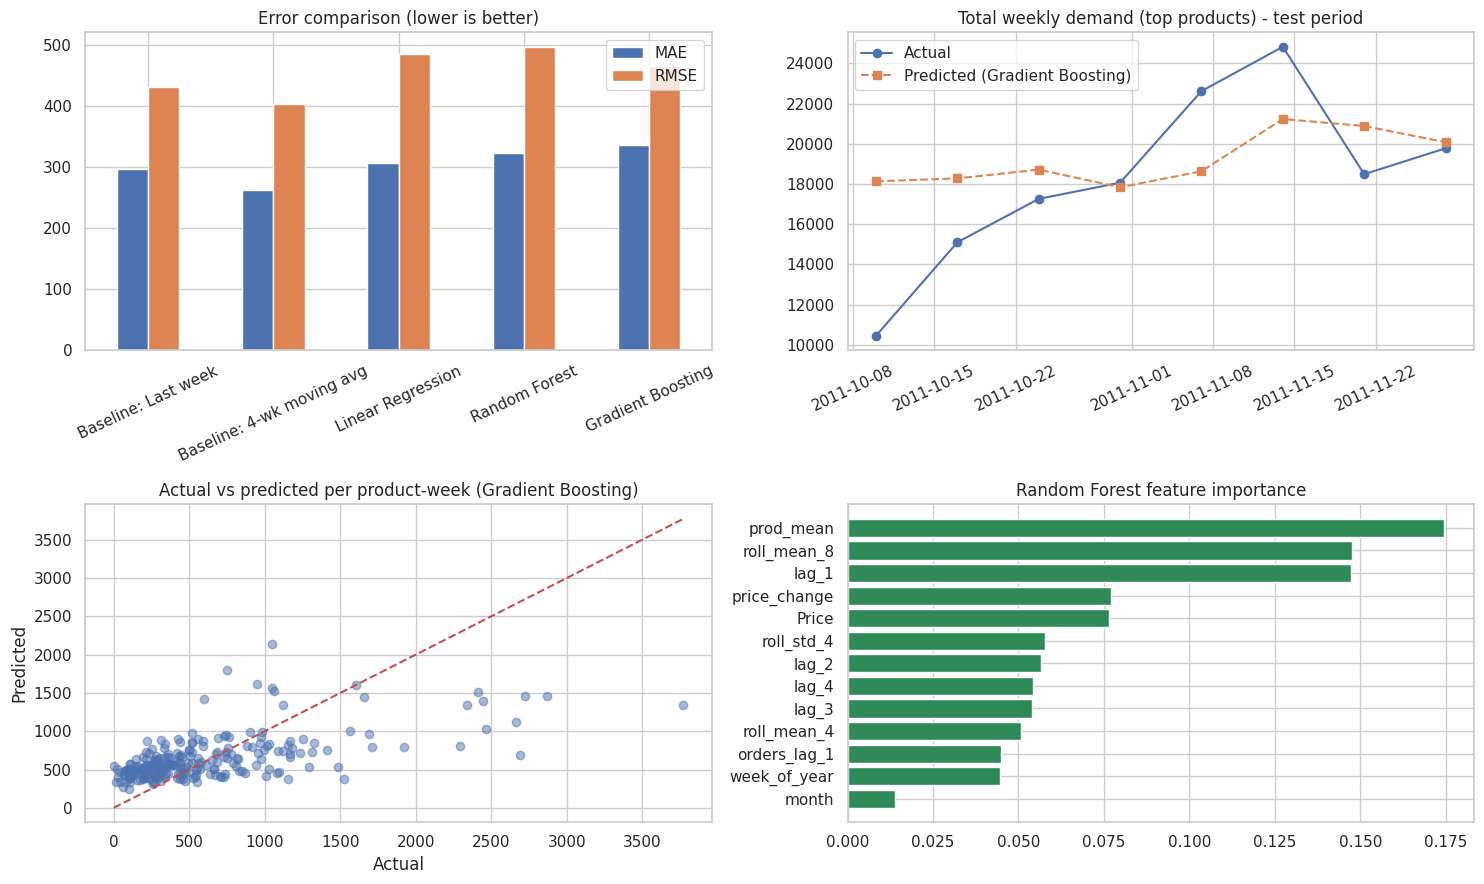

Best ML model: Gradient Boosting


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

results[["MAE", "RMSE"]].plot.bar(ax=axes[0, 0], color=["#4c72b0", "#dd8452"])
axes[0, 0].set_title("Error comparison (lower is better)"); axes[0, 0].tick_params(axis="x", rotation=25)

best_name = results.loc[[n for n in models]].sort_values("RMSE").index[0]
tt = test.assign(pred=np.clip(preds[best_name], 0, None))
agg = tt.groupby("Week")[["Quantity", "pred"]].sum()
axes[0, 1].plot(agg.index, agg["Quantity"], marker="o", label="Actual")
axes[0, 1].plot(agg.index, agg["pred"], marker="s", linestyle="--", label=f"Predicted ({best_name})")
axes[0, 1].set_title("Total weekly demand (top products) - test period"); axes[0, 1].legend()
axes[0, 1].tick_params(axis="x", rotation=25)

axes[1, 0].scatter(tt["Quantity"], tt["pred"], alpha=0.5)
lim = max(tt["Quantity"].max(), tt["pred"].max())
axes[1, 0].plot([0, lim], [0, lim], "r--"); axes[1, 0].set_xlabel("Actual"); axes[1, 0].set_ylabel("Predicted")
axes[1, 0].set_title(f"Actual vs predicted per product-week ({best_name})")

rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FEATS).sort_values()
axes[1, 1].barh(imp.index, imp.values, color="seagreen")
axes[1, 1].set_title("Random Forest feature importance")
plt.tight_layout(); plt.show()
print("Best ML model:", best_name)

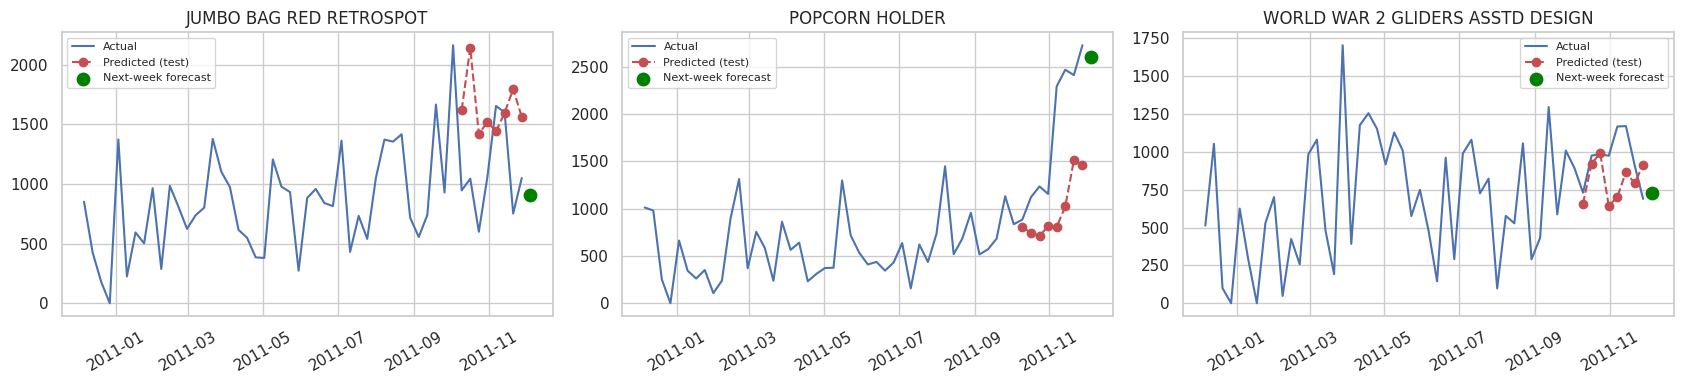

Forecast of units demanded for week starting 2011-12-05


,StockCode,Product,Forecast
0,23084,RABBIT NIGHT LIGHT,3139.0
1,22197,POPCORN HOLDER,2604.0
2,22086,PAPER CHAIN KIT 50'S CHRISTMAS,1657.0
3,22952,60 CAKE CASES VINTAGE CHRISTMAS,1012.0
4,84879,ASSORTED COLOUR BIRD ORNAMENT,955.0
5,85099B,JUMBO BAG RED RETROSPOT,909.0
6,85123A,WHITE HANGING HEART T-LIGHT HOLDER,732.0
7,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,725.0
8,23203,JUMBO BAG VINTAGE DOILY,658.0
9,84946,ANTIQUE SILVER T-LIGHT GLASS,574.0


In [ ]:
# Forecast for individual products: history, test-period actual vs predicted, and next-week forecast
best_model = models[best_name]
future_rows = grid[is_future].copy()
future_rows["prod_mean"] = future_rows["StockCode"].map(prod_mean)
future_rows = future_rows.dropna(subset=BASE_FEATS)

# refit on ALL available history (train + test) before forecasting the unseen next week
full = pd.concat([train, test])
best_model.fit(full[FEATS], full["Quantity"])
future_rows["Forecast"] = np.clip(best_model.predict(future_rows[FEATS]), 0, None).round(0)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, code in zip(axes, list(top_products[:3])):
    h = grid[(grid["StockCode"] == code) & (~is_future)]
    ax.plot(h["Week"], h["Quantity"], label="Actual")
    p = tt[tt["StockCode"] == code]
    ax.plot(p["Week"], p["pred"], "r--o", label="Predicted (test)")
    f = future_rows[future_rows["StockCode"] == code]
    ax.scatter(f["Week"], f["Forecast"], color="green", s=80, zorder=5, label="Next-week forecast")
    ax.set_title(name_map[code][:32]); ax.tick_params(axis="x", rotation=30); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

next_week = (future_rows.assign(Product=future_rows["StockCode"].map(name_map))
             [["StockCode", "Product", "Forecast"]].sort_values("Forecast", ascending=False))
print(f"Forecast of units demanded for week starting {future_week.date()}")
next_week.head(10).reset_index(drop=True)

## 6. Pattern mining - frequently purchased product combinations
We build an order x product basket matrix (top items only), run **FP-Growth** to find frequent itemsets, and derive **association rules** measured by *support*, *confidence* and *lift* (lift > 1 means products are bought together more often than by chance).

In [ ]:
item_orders = df.groupby("StockCode")["InvoiceNo"].nunique().nlargest(TOP_ITEMS_MINING).index
bk = df[df["StockCode"].isin(item_orders)][["InvoiceNo", "StockCode"]].drop_duplicates()
basket = pd.crosstab(bk["InvoiceNo"], bk["StockCode"]) > 0
basket = basket[basket.sum(axis=1) >= 2]
print(f"Basket matrix: {basket.shape[0]:,} orders x {basket.shape[1]} items")

def mine_rules(basket, supports=(0.02, 0.015, 0.01, 0.007, 0.005), min_rules=15):
    for s in supports:
        freq = fpgrowth(basket, min_support=s, use_colnames=True)
        if len(freq) == 0:
            continue
        try:
            rules = association_rules(freq, metric="lift", min_threshold=1.2)
        except TypeError:
            rules = association_rules(freq, num_itemsets=len(basket), metric="lift", min_threshold=1.2)
        rules = rules[rules["confidence"] >= 0.2]
        if len(rules) >= min_rules:
            break
    return s, freq, rules

min_sup, freq_items, rules = mine_rules(basket)
nm = lambda fs: ", ".join(name_map[i][:28] for i in sorted(fs))
rules = rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)
rules["rule"] = rules["antecedents"].apply(nm) + "  =>  " + rules["consequents"].apply(nm)
print(f"min_support = {min_sup} | frequent itemsets = {len(freq_items)} | rules (lift>=1.2, conf>=0.2) = {len(rules)}")
rules[["rule", "support", "confidence", "lift"]].head(15).round(3)

Basket matrix: 14,165 orders x 150 items
min_support = 0.02 | frequent itemsets = 460 | rules (lift>=1.2, conf>=0.2) = 748


,rule,support,confidence,lift
0,"REGENCY CAKESTAND 3 TIER, PINK REGENCY TEACUP ...",0.021,0.768,14.181
1,"GREEN REGENCY TEACUP AND SAU, ROSES REGENCY TE...",0.021,0.392,14.181
2,"REGENCY CAKESTAND 3 TIER, GREEN REGENCY TEACUP...",0.021,0.591,14.008
3,"PINK REGENCY TEACUP AND SAUC, ROSES REGENCY TE...",0.021,0.503,14.008
4,"REGENCY CAKESTAND 3 TIER, GREEN REGENCY TEACUP...",0.021,0.738,13.841
5,PINK REGENCY TEACUP AND SAUC => REGENCY CAKE...,0.021,0.399,13.841
6,HAND WARMER SCOTTY DOG DESIG => HAND WARMER ...,0.020,0.527,13.692
7,HAND WARMER BIRD DESIGN => HAND WARMER SCOTT...,0.020,0.523,13.692
8,HAND WARMER OWL DESIGN => HAND WARMER SCOTTY...,0.024,0.519,13.599
9,HAND WARMER SCOTTY DOG DESIG => HAND WARMER ...,0.024,0.619,13.599


### Visualisations 9-10: rule quality and top combinations

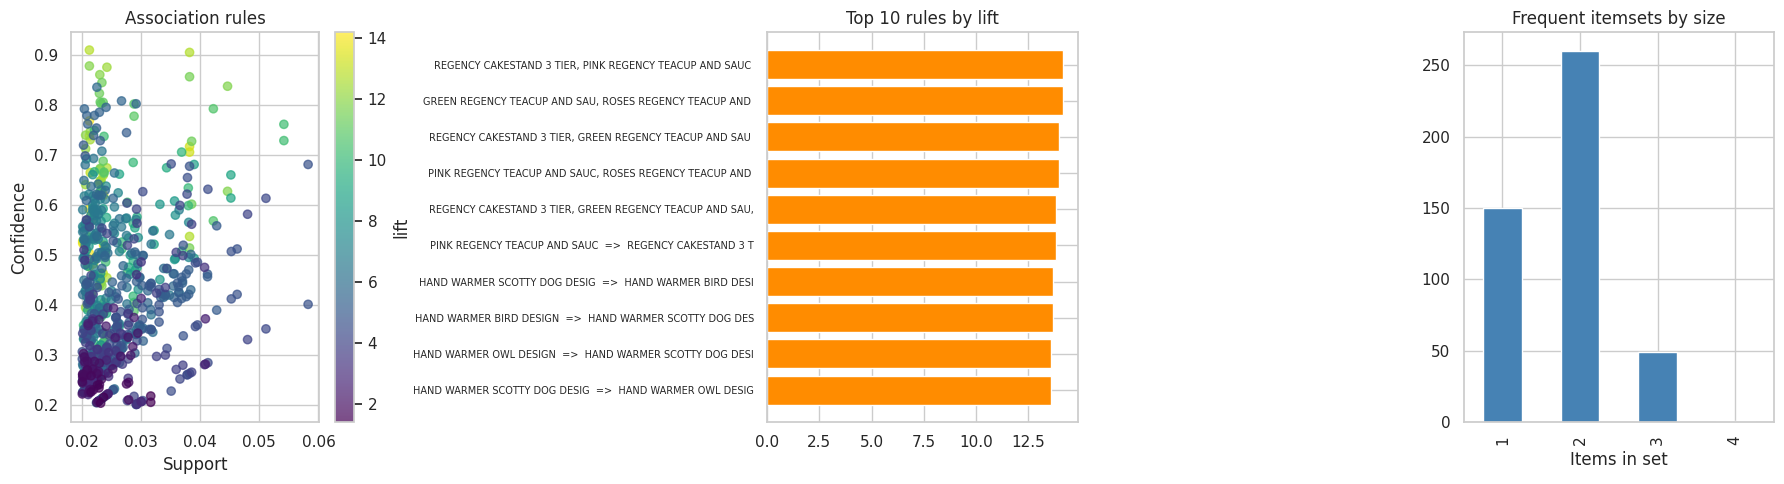

Most frequent product pairs / triples:


,products,support
0,"JUMBO BAG PINK POLKADOT, JUMBO BAG RED RETROSPOT",0.0582
1,"GREEN REGENCY TEACUP AND SAU, ROSES REGENCY TE...",0.0541
2,"JUMBO STORAGE BAG SUKI, JUMBO BAG RED RETROSPOT",0.0511
3,"JUMBO SHOPPER VINTAGE RED PA, JUMBO BAG RED RE...",0.0480
4,"LUNCH BAG RED RETROSPOT, LUNCH BAG SUKI DESIGN",0.0462
5,"LUNCH BAG RED RETROSPOT, LUNCH BAG BLACK SKULL.",0.0453
6,"ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELI...",0.0452
7,"GREEN REGENCY TEACUP AND SAU, PINK REGENCY TEA...",0.0446


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
if len(rules):
    sc = axes[0].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=0.7)
    plt.colorbar(sc, ax=axes[0], label="lift")
    axes[0].set_xlabel("Support"); axes[0].set_ylabel("Confidence"); axes[0].set_title("Association rules")

    top_r = rules.head(10).iloc[::-1]
    axes[1].barh([r[:55] for r in top_r["rule"]], top_r["lift"], color="darkorange")
    axes[1].set_title("Top 10 rules by lift"); axes[1].tick_params(axis="y", labelsize=7)

freq_items["size"] = freq_items["itemsets"].apply(len)
freq_items["size"].value_counts().sort_index().plot.bar(ax=axes[2], color="steelblue")
axes[2].set_title("Frequent itemsets by size"); axes[2].set_xlabel("Items in set")
plt.tight_layout(); plt.show()

print("Most frequent product pairs / triples:")
pairs = freq_items[freq_items["size"] >= 2].sort_values("support", ascending=False).head(8).copy()
pairs["products"] = pairs["itemsets"].apply(nm)
pairs[["products", "support"]].round(4).reset_index(drop=True)

## 7. Recommender system
**Data:** customer x product implicit-feedback matrix (1 = bought). Customers with >= 5 distinct products and products with >= 5 buyers are kept.

**Split:** for every customer, 20 % of purchased products are hidden as the test set. Models must predict these hidden products from the remaining 80 %.

**Models:** Popularity (baseline), Item-based Collaborative Filtering (cosine), User-based CF (top-50 neighbours), Matrix factorisation (Truncated SVD).

**Metrics @K:** Precision, Recall, Hit-rate, NDCG, and catalogue Coverage.

In [ ]:
cust = df.dropna(subset=["CustomerID"])[["CustomerID", "StockCode"]].drop_duplicates()
for _ in range(3):  # iterative filtering
    cust = cust[cust.groupby("CustomerID")["StockCode"].transform("nunique") >= 5]
    cust = cust[cust.groupby("StockCode")["CustomerID"].transform("nunique") >= 5]

users = pd.Index(sorted(cust["CustomerID"].unique())); items = pd.Index(sorted(cust["StockCode"].unique()))
cust = cust.assign(u=users.get_indexer(cust["CustomerID"]), i=items.get_indexer(cust["StockCode"]))

cust = cust.sample(frac=1, random_state=SEED)
cust["rank"] = cust.groupby("u").cumcount()
cust["n"] = cust.groupby("u")["u"].transform("size")
cust["is_test"] = cust["rank"] < np.maximum(1, (0.2 * cust["n"]).round())

n_users, n_items = len(users), len(items)
mk = lambda d: sparse.csr_matrix((np.ones(len(d), dtype=np.float32), (d["u"], d["i"])), shape=(n_users, n_items))
R_train, R_test, R_full = mk(cust[~cust["is_test"]]), mk(cust[cust["is_test"]]), mk(cust)
density = R_full.nnz / (n_users * n_items)
print(f"Users: {n_users:,} | Items: {n_items:,} | Interactions: {R_full.nnz:,} | Density: {density:.2%}")
print(f"Train interactions: {R_train.nnz:,} | Test interactions: {R_test.nnz:,}")

Users: 4,074 | Items: 3,146 | Interactions: 264,538 | Density: 2.06%
Train interactions: 211,620 | Test interactions: 52,918


In [ ]:
def top_k_users(k_neighbors, S):
    """Keep only the k strongest neighbours per row of a similarity matrix."""
    S = S.copy()
    idx = np.argpartition(-S, k_neighbors, axis=1)[:, k_neighbors:]
    np.put_along_axis(S, idx, 0, axis=1)
    return S

def score_popularity(R):
    return np.tile(np.asarray(R.sum(axis=0)).ravel(), (R.shape[0], 1)).astype(np.float32)

def item_similarity(R):
    S = cosine_similarity(R.T.tocsr()); np.fill_diagonal(S, 0); return S

def score_item_cf(R):
    return np.asarray(R @ item_similarity(R))

def score_user_cf(R, neighbours=50):
    S = cosine_similarity(R); np.fill_diagonal(S, 0)
    S = top_k_users(min(neighbours, S.shape[0] - 1), S)
    return np.asarray(S @ R)

def score_svd(R, factors=40):
    svd = TruncatedSVD(n_components=factors, random_state=SEED)
    Z = svd.fit_transform(R)
    return Z @ svd.components_

def evaluate_recs(scores, R_train, R_test, k=10):
    sc = np.array(scores, dtype=np.float32)
    r, c = R_train.nonzero(); sc[r, c] = -np.inf                       # never recommend already-bought items
    topk = np.argpartition(-sc, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(sc, topk, axis=1), axis=1)
    topk = np.take_along_axis(topk, order, axis=1)
    test_dense = R_test.toarray() > 0
    hits = np.take_along_axis(test_dense, topk, axis=1)
    n_rel = test_dense.sum(axis=1)
    disc = 1 / np.log2(np.arange(2, k + 2))
    dcg = (hits * disc).sum(axis=1)
    idcg = np.array([disc[:min(n, k)].sum() for n in n_rel])
    valid = n_rel > 0
    return {f"Precision@{k}": (hits.sum(1) / k)[valid].mean(),
            f"Recall@{k}": (hits.sum(1) / np.maximum(n_rel, 1))[valid].mean(),
            f"HitRate@{k}": hits.any(axis=1)[valid].mean(),
            f"NDCG@{k}": (dcg / np.maximum(idcg, 1e-9))[valid].mean(),
            "Coverage": len(np.unique(topk)) / R_train.shape[1]}

rec_models = {"Popularity (baseline)": score_popularity, "Item-based CF": score_item_cf,
              "User-based CF": score_user_cf, "SVD (matrix factorisation)": score_svd}
rec_results = pd.DataFrame({n: evaluate_recs(f(R_train), R_train, R_test, K) for n, f in rec_models.items()}).T
print(f"Recommendation performance (K={K}) on hidden purchases")
rec_results.round(4).sort_values(f"NDCG@{K}", ascending=False)

Recommendation performance (K=10) on hidden purchases


,Precision@10,Recall@10,HitRate@10,NDCG@10,Coverage
SVD (matrix factorisation),0.1395,0.1455,0.6495,0.1954,0.2133
User-based CF,0.1263,0.1499,0.6517,0.1913,0.3398
Item-based CF,0.1125,0.1508,0.6159,0.1817,0.3973
Popularity (baseline),0.0410,0.0373,0.2904,0.0518,0.0121


### Visualisation 11: recommender comparison

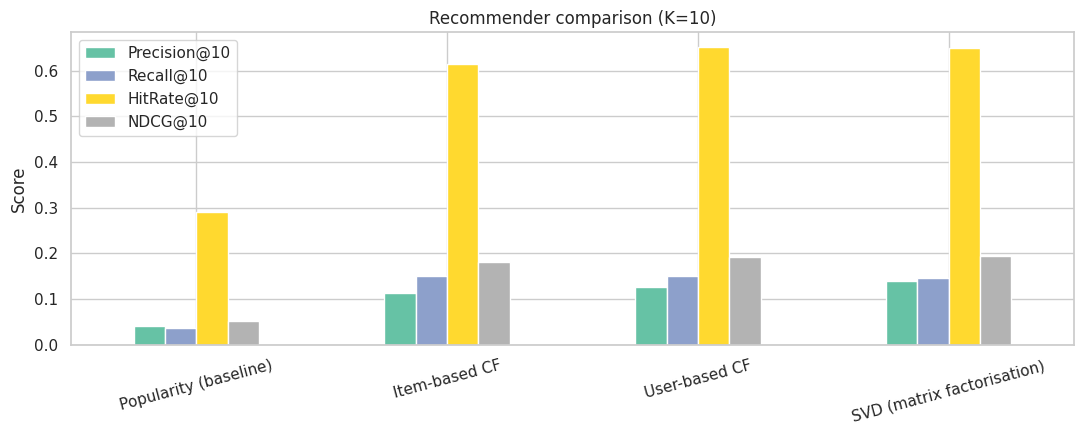

Best recommender by NDCG: SVD (matrix factorisation)


In [ ]:
metrics = [f"Precision@{K}", f"Recall@{K}", f"HitRate@{K}", f"NDCG@{K}"]
ax = rec_results[metrics].plot.bar(figsize=(11, 4.5), colormap="Set2")
ax.set_title(f"Recommender comparison (K={K})"); ax.set_ylabel("Score"); ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
best_rec = rec_results[f"NDCG@{K}"].idxmax()
print("Best recommender by NDCG:", best_rec)

## 8. Demonstration - input -> processing -> output
Final models are refit on the full purchase history. Three demos:
1. Recommend products for an existing customer
2. Recommend products for a *new basket* of items (works for anonymous shoppers)
3. "Frequently bought together" lookup from mined association rules

In [ ]:
S_full = item_similarity(R_full)                      # item-item similarity on all data
pop_full = np.asarray(R_full.sum(axis=0)).ravel()
item_names = [name_map[c] for c in items]

def recommend_for_customer(customer_id, k=5):
    customer_id = str(customer_id)
    if customer_id not in users:                       # cold start -> popularity
        print("Unknown customer -> showing most popular products")
        top = np.argsort(-pop_full)[:k]
        return pd.DataFrame({"Recommended product": [item_names[i] for i in top]})
    u = users.get_loc(customer_id)
    bought = R_full[u].indices
    s = np.asarray(R_full[u] @ S_full).ravel(); s[bought] = -np.inf
    top = np.argsort(-s)[:k]
    print(f"Customer {customer_id} | previously bought {len(bought)} products, e.g.:")
    for i in bought[:5]: print("   -", item_names[i])
    return pd.DataFrame({"Recommended product": [item_names[i] for i in top],
                         "Score": np.round(s[top], 3)})

def recommend_for_basket(stock_codes, k=5):
    idx = [items.get_loc(c) for c in stock_codes if c in items]
    s = S_full[idx].sum(axis=0); s[idx] = -np.inf
    top = np.argsort(-s)[:k]
    return pd.DataFrame({"Recommended product": [item_names[i] for i in top], "Score": np.round(s[top], 3)})

def bought_together(stock_code, k=5):
    r = rules[rules["antecedents"].apply(lambda a: stock_code in a)]
    return r[["rule", "confidence", "lift"]].head(k).round(3)

demo_customer = users[0]
print("=== DEMO 1: customer recommendations ===")
print(recommend_for_customer(demo_customer, k=5).to_string(index=False))

demo_basket = list(items[:2])
print("\n=== DEMO 2: basket-based recommendations ===")
print("Basket:", [name_map[c] for c in demo_basket])
print(recommend_for_basket(demo_basket, k=5).to_string(index=False))

if len(rules):
    seed_item = list(rules.iloc[0]["antecedents"])[0]
    print("\n=== DEMO 3: frequently bought together ===")
    print("Product:", name_map[seed_item])
    print(bought_together(seed_item).to_string(index=False))

=== DEMO 1: customer recommendations ===
Customer 12347 | previously bought 103 products, e.g.:
   - SMALL FOLDING SCISSOR(POINTED EDGE)
   - NAMASTE SWAGAT INCENSE
   - RED RETROSPOT PURSE
   - WOODLAND CHARLOTTE BAG
   - BLACK EAR MUFF HEADPHONES
               Recommended product     Score
   PACK OF 72 RETROSPOT CAKE CASES 16.021999
           LUNCH BAG RED RETROSPOT 15.437000
        SET OF 3 REGENCY CAKE TINS 15.343000
         LUNCH BAG SPACEBOY DESIGN 15.104000
PACK OF 60 PINK PAISLEY CAKE CASES 14.840000

=== DEMO 2: basket-based recommendations ===
Basket: ['INFLATABLE POLITICAL GLOBE', 'GROOVY CACTUS INFLATABLE']
                Recommended product  Score
MAGIC SHEEP WOOL GROWING FROM PAPER  0.263
          ENGLISH ROSE SPIRIT LEVEL  0.263
  COWBOYS AND INDIANS BIRTHDAY CARD  0.261
           ELEPHANT, BIRTHDAY CARD,  0.258
     ASSORTED TUTTI FRUTTI BRACELET  0.257

=== DEMO 3: frequently bought together ===
Product: PINK REGENCY TEACUP AND SAUCER
                          

## 9. Summary and export

In [ ]:
import os
os.makedirs("outputs", exist_ok=True)
results.to_csv("outputs/demand_forecast_metrics.csv")
next_week.to_csv("outputs/next_week_demand_forecast.csv", index=False)
rules.drop(columns=["antecedents", "consequents"], errors="ignore").to_csv("outputs/association_rules.csv", index=False)
rec_results.to_csv("outputs/recommender_metrics.csv")

best_f = results.loc[best_name]
base_f = results.loc["Baseline: Last week"]
print("=" * 60)
print(f"Dataset                : {DATASET_NAME}")
print(f"Demand forecasting     : best = {best_name}")
print(f"   RMSE {best_f['RMSE']:.2f} vs baseline {base_f['RMSE']:.2f} "
      f"({100 * (1 - best_f['RMSE'] / base_f['RMSE']):.1f}% improvement) | WAPE {best_f['WAPE %']:.1f}% | R2 {best_f['R2']:.2f}")
print(f"Pattern mining         : {len(freq_items)} frequent itemsets, {len(rules)} rules (min_support={min_sup})")
if len(rules):
    print(f"   strongest rule: {rules.iloc[0]['rule']} (lift {rules.iloc[0]['lift']:.2f})")
bp = rec_results.loc[best_rec]; pp = rec_results.loc["Popularity (baseline)"]
print(f"Recommender            : best = {best_rec}")
print(f"   NDCG@{K} {bp[f'NDCG@{K}']:.3f} vs popularity {pp[f'NDCG@{K}']:.3f} | HitRate@{K} {bp[f'HitRate@{K}']:.3f}")
print("Files saved in ./outputs/")
print("=" * 60)

Dataset                : UCI Online Retail
Demand forecasting     : best = Gradient Boosting
   RMSE 465.52 vs baseline 431.88 (-7.8% improvement) | WAPE 55.2% | R2 0.36
Pattern mining         : 460 frequent itemsets, 748 rules (min_support=0.02)
   strongest rule: REGENCY CAKESTAND 3 TIER, PINK REGENCY TEACUP AND SAUC  =>  GREEN REGENCY TEACUP AND SAU, ROSES REGENCY TEACUP AND SAU (lift 14.18)
Recommender            : best = SVD (matrix factorisation)
   NDCG@10 0.195 vs popularity 0.052 | HitRate@10 0.649
Files saved in ./outputs/
